# Hospital Management & Analytics System
## Pandas Data Cleaning + EDA

**Level:** Simple Student Version

### Steps
1. Read CSV files
2. Explore data
3. Check missing values
4. Check and remove duplicates
5. Clean text
6. Convert dates and numbers
7. Save cleaned data
8. Perform basic EDA


## ============================================================

In [108]:
# Hospital Management & Analytics System
# Pandas Cleaning + EDA
# Simple Student Version
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PART 1: DATA CLEANING
# ============================================================

In [109]:
from pathlib import Path

CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

print("Cleaned folder is ready:", CLEAN_PATH)

Cleaned folder is ready: ..\data\cleaned


In [110]:
from pathlib import Path

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned file
df_departments.to_csv(
    CLEAN_PATH / "Departments.csv",
    index=False
)

print("Departments.csv saved successfully!")

Departments.csv saved successfully!


In [111]:
import glob
import os

files = glob.glob("../data/raw/*.csv")

print("Number of CSV files:", len(files))

for file in files:
    print(os.path.basename(file))

Number of CSV files: 12
admissions.csv
appointments.csv
attendance.csv
departments.csv
employees.csv
invoices.csv
medical_records.csv
medicines.csv
patients.csv
payments.csv
prescriptions.csv
rooms.csv


In [112]:
import pandas as pd
import glob
import os

RAW_PATH = "../data/raw"

data = {}

for file in glob.glob(f"{RAW_PATH}/*.csv"):
    name = os.path.basename(file).replace(".csv", "")
    data[name] = pd.read_csv(file)

print("Files loaded successfully:", len(data))

for name, df in data.items():
    print(f"{name}: {df.shape}")

Files loaded successfully: 12
admissions: (656, 7)
appointments: (2424, 7)
attendance: (3535, 7)
departments: (12, 4)
employees: (525, 10)
invoices: (1111, 12)
medical_records: (1818, 7)
medicines: (242, 8)
patients: (1212, 9)
payments: (1666, 5)
prescriptions: (1818, 7)
rooms: (222, 6)


In [113]:
for name, df in data.items():

    print("\n" + "=" * 60)
    print(f"FILE: {name}")
    print("=" * 60)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicates:", df.duplicated().sum())


FILE: admissions
Shape: (656, 7)

Columns:
['AdmissionID', 'PatientID', 'RoomID', 'DoctorID', 'AdmissionDate', 'DischargeDate', 'Status']

Missing values:
AdmissionID      0
PatientID        6
RoomID           6
DoctorID         6
AdmissionDate    6
DischargeDate    6
Status           6
dtype: int64

Duplicates: 6

FILE: appointments
Shape: (2424, 7)

Columns:
['AppointmentID', 'PatientID', 'DoctorID', 'AppointmentDate', 'AppointmentTime', 'Status', 'Reason']

Missing values:
AppointmentID       0
PatientID          24
DoctorID           24
AppointmentDate    24
AppointmentTime    24
Status             25
Reason             25
dtype: int64

Duplicates: 24

FILE: attendance
Shape: (3535, 7)

Columns:
['AttendanceID', 'EmployeeID', 'AttendanceDate', 'CheckIn', 'CheckOut', 'Status', 'WorkingHours']

Missing values:
AttendanceID       0
EmployeeID        35
AttendanceDate    35
CheckIn           36
CheckOut          35
Status            36
WorkingHours      35
dtype: int64

Duplicates: 34

## 1. Departments

In [114]:
import pandas as pd
from pathlib import Path

# Read Departments file
df_departments = pd.read_csv("../data/raw/departments.csv")

# Explore data
print(df_departments.head())
print(df_departments.info())

# Check missing values
print(df_departments.isnull().sum())

# Check duplicates
print("Duplicates:", df_departments.duplicated().sum())

# Remove duplicates
df_departments = df_departments.drop_duplicates()

# Clean text columns
df_departments["DepartmentName"] = (
    df_departments["DepartmentName"]
    .str.strip()
    .str.title()
)

df_departments["Location"] = (
    df_departments["Location"]
    .str.strip()
    .str.title()
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_departments.to_csv(
    CLEAN_PATH / "departments.csv",
    index=False
)

print("Departments cleaned and saved successfully!")

   DepartmentID DepartmentName        Location       Phone
0             1      Emergency      Building C  1095822412
1             2     Cardiology    building a    1024942603
2             3     Pediatrics      Building C  1013356886
3             4    Orthopedics      Building C  1046913810
4             5    neurology        Building A  1042868828
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   DepartmentID    12 non-null     int64 
 1   DepartmentName  12 non-null     object
 2   Location        12 non-null     object
 3   Phone           12 non-null     int64 
dtypes: int64(2), object(2)
memory usage: 516.0+ bytes
None
DepartmentID      0
DepartmentName    0
Location          0
Phone             0
dtype: int64
Duplicates: 0
Departments cleaned and saved successfully!


In [115]:
for name, df in data.items():
    print(
        f"{name:20} | "
        f"Rows: {df.shape[0]:4} | "
        f"Columns: {df.shape[1]:2} | "
        f"Missing: {df.isnull().sum().sum():3} | "
        f"Duplicates: {df.duplicated().sum():3}"
    )

admissions           | Rows:  656 | Columns:  7 | Missing:  36 | Duplicates:   6
appointments         | Rows: 2424 | Columns:  7 | Missing: 146 | Duplicates:  24
attendance           | Rows: 3535 | Columns:  7 | Missing: 212 | Duplicates:  34
departments          | Rows:   12 | Columns:  4 | Missing:   0 | Duplicates:   0
employees            | Rows:  525 | Columns: 10 | Missing:  46 | Duplicates:   5
invoices             | Rows: 1111 | Columns: 12 | Missing: 122 | Duplicates:  11
medical_records      | Rows: 1818 | Columns:  7 | Missing: 110 | Duplicates:  18
medicines            | Rows:  242 | Columns:  8 | Missing:  15 | Duplicates:   2
patients             | Rows: 1212 | Columns:  9 | Missing:  96 | Duplicates:  12
payments             | Rows: 1666 | Columns:  5 | Missing:  66 | Duplicates:  16
prescriptions        | Rows: 1818 | Columns:  7 | Missing: 108 | Duplicates:  18
rooms                | Rows:  222 | Columns:  6 | Missing:  10 | Duplicates:   2


## 2. Employees

In [116]:
import pandas as pd
from pathlib import Path

# Read Employees file
df_employees = pd.read_csv("../data/raw/employees.csv")

# Explore data
print(df_employees.head())
print(df_employees.info())

# Check missing values
print(df_employees.isnull().sum())

# Check duplicates
print("Duplicates:", df_employees.duplicated().sum())

# Remove duplicates
df_employees = df_employees.drop_duplicates()

# Clean text columns
text_columns = df_employees.select_dtypes(include="object").columns

for col in text_columns:
    df_employees[col] = (
        df_employees[col]
        .str.strip()
        .str.title()
    )

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_employees.to_csv(
    CLEAN_PATH / "employees.csv",
    index=False
)

print("Employees cleaned and saved successfully!")

   EmployeeID       FullName      JobTitle  DepartmentID         Phone  \
0           1  Employee 0001    Pharmacist           NaN  1.013999e+09   
1           2  Employee 0002    Accountant           5.0  1.039345e+09   
2           3  Employee 0003  Receptionist           7.0  1.177828e+09   
3           4  Employee 0004        Doctor           6.0  1.085329e+09   
4           5  Employee 0005       Manager          12.0  1.197226e+09   

                       Email   Salary    HireDate    Shift  Status  
0  employee0001@hospital.com  17342.0  2026-02-02  Morning  Active  
1  employee0002@hospital.com  13038.0  2025-05-23    Night  Active  
2  employee0003@hospital.com  21002.0  2026-05-02  Evening  Active  
3  employee0004@hospital.com  18087.0  2026-07-14    Night  Active  
4  employee0005@hospital.com   9873.0  2026-07-13  Evening  Active  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525 entries, 0 to 524
Data columns (total 10 columns):
 #   Column        Non-Null Count  D

## 3. Patients

In [117]:
import pandas as pd
from pathlib import Path

# Read Patients file
df_patients = pd.read_csv("../data/raw/patients.csv")

# Explore data
print(df_patients.head())
print(df_patients.info())

# Check missing values
print(df_patients.isnull().sum())

# Check duplicates
print("Duplicates:", df_patients.duplicated().sum())

# Remove duplicates
df_patients = df_patients.drop_duplicates()

# Clean text columns
df_patients["FullName"] = (
    df_patients["FullName"]
    .str.strip()
    .str.title()
)

df_patients["Gender"] = (
    df_patients["Gender"]
    .str.strip()
    .str.title()
)

df_patients["BloodType"] = (
    df_patients["BloodType"]
    .str.strip()
    .str.upper()
)

# Convert date columns
df_patients["DateOfBirth"] = pd.to_datetime(
    df_patients["DateOfBirth"],
    errors="coerce"
)

df_patients["RegistrationDate"] = pd.to_datetime(
    df_patients["RegistrationDate"],
    errors="coerce"
)

# Fill missing Gender values
df_patients["Gender"] = df_patients["Gender"].fillna("Unknown")

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_patients.to_csv(
    CLEAN_PATH / "patients.csv",
    index=False
)

print("Patients cleaned and saved successfully!")

   PatientID       FullName  Gender DateOfBirth         Phone  \
0          1  Patient 00001  Female  1976-10-10  1.210405e+09   
1          2  Patient 00002    Male  1951-06-20  1.187620e+09   
2          3  Patient 00003  Female  1980-08-16  1.016079e+09   
3          4  Patient 00004  Female  2011-07-29  1.556242e+09   
4          5  Patient 00005    Male  1948-10-18  1.082634e+09   

               Address BloodType  EmergencyContact RegistrationDate  
0  Street 142, City 18       AB-      1.249146e+09       2026-07-13  
1   Street 124, City 6       AB+      1.078970e+09       2025-01-27  
2   Street 95, City 18       AB+      1.194293e+09       2026-02-23  
3  Street 143, City 16       AB-      1.122685e+09       2024-10-14  
4   Street 65, City 10        O-      1.182976e+09       2024-08-13  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            -------------

## 4. Attendance

In [118]:
import pandas as pd
from pathlib import Path

# Read Attendance file
df_attendance = pd.read_csv("../data/raw/attendance.csv")

# Explore data
print(df_attendance.head())
print(df_attendance.info())

# Check missing values
print(df_attendance.isnull().sum())

# Check duplicates
print("Duplicates:", df_attendance.duplicated().sum())

# Remove duplicates
df_attendance = df_attendance.drop_duplicates()

# Convert AttendanceDate to datetime
df_attendance["AttendanceDate"] = pd.to_datetime(
    df_attendance["AttendanceDate"],
    errors="coerce"
)

# Clean Status
df_attendance["Status"] = (
    df_attendance["Status"]
    .str.strip()
    .str.title()
)

# Convert WorkingHours to numeric
df_attendance["WorkingHours"] = pd.to_numeric(
    df_attendance["WorkingHours"],
    errors="coerce"
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_attendance.to_csv(
    CLEAN_PATH / "attendance.csv",
    index=False
)

print("Attendance cleaned and saved successfully!")

   AttendanceID  EmployeeID AttendanceDate CheckIn CheckOut   Status  \
0             1       215.0     2025-06-18   08:43    15:01  Present   
1             2       134.0     2026-01-29   10:16    16:44     Late   
2             3       285.0     2024-09-17   10:02    23:24  Present   
3             4       126.0     2026-08-06   07:40    22:27  Present   
4             5       439.0     2024-05-04   10:35    21:07  Present   

   WorkingHours  
0          7.59  
1          2.66  
2          1.51  
3          7.01  
4          2.58  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3535 entries, 0 to 3534
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   AttendanceID    3535 non-null   int64  
 1   EmployeeID      3500 non-null   float64
 2   AttendanceDate  3500 non-null   object 
 3   CheckIn         3499 non-null   object 
 4   CheckOut        3500 non-null   object 
 5   Status          3499 non-null   o

## 5. Appointments

In [119]:
import pandas as pd
from pathlib import Path

# Read Appointments file
df_appointments = pd.read_csv("../data/raw/appointments.csv")

# Explore data
print(df_appointments.head())
print(df_appointments.info())

# Check missing values
print(df_appointments.isnull().sum())

# Check duplicates
print("Duplicates:", df_appointments.duplicated().sum())

# Remove duplicates
df_appointments = df_appointments.drop_duplicates()

# Convert AppointmentDate to datetime
df_appointments["AppointmentDate"] = pd.to_datetime(
    df_appointments["AppointmentDate"],
    errors="coerce"
)

# Clean Status
df_appointments["Status"] = (
    df_appointments["Status"]
    .str.strip()
    .str.title()
)

# Clean Reason
df_appointments["Reason"] = (
    df_appointments["Reason"]
    .str.strip()
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_appointments.to_csv(
    CLEAN_PATH / "appointments.csv",
    index=False
)

print("Appointments cleaned and saved successfully!")

   AppointmentID  PatientID  DoctorID AppointmentDate AppointmentTime  \
0              1      347.0     117.0      2026-04-04           15:30   
1              2     1056.0       4.0      2025-06-04           10:15   
2              3      908.0      26.0      2025-11-09           13:30   
3              4     1024.0     348.0      2024-12-31           08:00   
4              5     1157.0       4.0      2025-10-11           12:00   

      Status         Reason  
0  Scheduled  Routine Check  
1    No Show   Consultation  
2  Completed   Consultation  
3  Scheduled           Pain  
4  Scheduled           Pain  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2424 entries, 0 to 2423
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   AppointmentID    2424 non-null   int64  
 1   PatientID        2400 non-null   float64
 2   DoctorID         2400 non-null   float64
 3   AppointmentDate  2400 non-null   object 

## 6. Admissions

In [120]:
import pandas as pd
from pathlib import Path

# Read Admissions file
df_admissions = pd.read_csv("../data/raw/admissions.csv")

# Explore data
print(df_admissions.head())
print(df_admissions.info())

# Check missing values
print(df_admissions.isnull().sum())

# Check duplicates
print("Duplicates:", df_admissions.duplicated().sum())

# Remove duplicates
df_admissions = df_admissions.drop_duplicates()

# Convert AdmissionDate to datetime
df_admissions["AdmissionDate"] = pd.to_datetime(
    df_admissions["AdmissionDate"],
    errors="coerce"
)

# Convert DischargeDate to datetime
df_admissions["DischargeDate"] = pd.to_datetime(
    df_admissions["DischargeDate"],
    errors="coerce"
)

# Clean Status
df_admissions["Status"] = (
    df_admissions["Status"]
    .str.strip()
    .str.title()
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_admissions.to_csv(
    CLEAN_PATH / "admissions.csv",
    index=False
)

print("Admissions cleaned and saved successfully!")

   AdmissionID  PatientID  RoomID  DoctorID AdmissionDate DischargeDate  \
0            1      105.0    11.0     448.0    2025-11-07    2025-11-20   
1            2      719.0   192.0     277.0    2025-08-28    2025-09-12   
2            3      439.0    92.0     418.0    2025-01-25    2025-02-14   
3            4      651.0   142.0     328.0    2024-12-08    2024-12-18   
4            5      509.0    39.0     394.0    2025-02-13    2025-03-03   

       Status  
0  Discharged  
1    Admitted  
2  Discharged  
3  Discharged  
4  Discharged  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 656 entries, 0 to 655
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   AdmissionID    656 non-null    int64  
 1   PatientID      650 non-null    float64
 2   RoomID         650 non-null    float64
 3   DoctorID       650 non-null    float64
 4   AdmissionDate  650 non-null    object 
 5   DischargeDate  650 non-null    objec

## 7. Medical Records

In [121]:
import pandas as pd
from pathlib import Path

# Read Medical Records file
df_medical = pd.read_csv("../data/raw/medical_records.csv")

# Explore data
print(df_medical.head())
print(df_medical.info())

# Check missing values
print(df_medical.isnull().sum())

# Check duplicates
print("Duplicates:", df_medical.duplicated().sum())

# Remove duplicates
df_medical = df_medical.drop_duplicates()

# Clean Diagnosis
df_medical["Diagnosis"] = (
    df_medical["Diagnosis"]
    .str.strip()
    .str.title()
)

# Clean Treatment
df_medical["Treatment"] = (
    df_medical["Treatment"]
    .str.strip()
    .str.title()
)

# Clean Notes
df_medical["Notes"] = (
    df_medical["Notes"]
    .str.strip()
)

# Convert RecordDate to datetime
df_medical["RecordDate"] = pd.to_datetime(
    df_medical["RecordDate"],
    errors="coerce"
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_medical.to_csv(
    CLEAN_PATH / "medical_records.csv",
    index=False
)

print("Medical Records cleaned and saved successfully!")

   MedicalRecordID  PatientID  DoctorID Diagnosis      Treatment  \
0                1      980.0      31.0  Fracture  Physiotherapy   
1                2      941.0     184.0    Asthma     Medication   
2                3      908.0     288.0  Fracture    Observation   
3                4        NaN      92.0  Fracture        Surgery   
4                5      278.0     428.0  Migraine     Medication   

                       Notes  RecordDate  
0      Routine clinical note  2024-02-17  
1    routine clinical note    2026-03-01  
2      Routine clinical note  2024-04-19  
3      Routine clinical note  2024-03-30  
4      Routine clinical note  2024-04-28  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1818 entries, 0 to 1817
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MedicalRecordID  1818 non-null   int64  
 1   PatientID        1800 non-null   float64
 2   DoctorID         1799 non-null   float

## 8. Medicines

In [122]:
import pandas as pd
from pathlib import Path

# Read Medicines file
df_medicines = pd.read_csv("../data/raw/medicines.csv")

# Explore data
print(df_medicines.head())
print(df_medicines.info())

# Check missing values
print(df_medicines.isnull().sum())

# Check duplicates
print("Duplicates:", df_medicines.duplicated().sum())

# Remove duplicates
df_medicines = df_medicines.drop_duplicates()

# Clean MedicineName
df_medicines["MedicineName"] = (
    df_medicines["MedicineName"]
    .str.strip()
    .str.title()
)

# Clean Category
df_medicines["Category"] = (
    df_medicines["Category"]
    .str.strip()
    .str.title()
)

# Clean SupplierName
df_medicines["SupplierName"] = (
    df_medicines["SupplierName"]
    .str.strip()
    .str.title()
)

# Convert Price to numeric
df_medicines["Price"] = pd.to_numeric(
    df_medicines["Price"],
    errors="coerce"
)

# Convert Quantity to numeric
df_medicines["Quantity"] = pd.to_numeric(
    df_medicines["Quantity"],
    errors="coerce"
)

# Convert ExpiryDate to datetime
df_medicines["ExpiryDate"] = pd.to_datetime(
    df_medicines["ExpiryDate"],
    errors="coerce"
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_medicines.to_csv(
    CLEAN_PATH / "medicines.csv",
    index=False
)

print("Medicines cleaned and saved successfully!")

   MedicineID  MedicineName   Category   Price  Quantity  ExpiryDate  \
0           1  Medicine 001    Cardiac  486.49     471.0  2030-03-11   
1           2  Medicine 002  Analgesic  970.08      21.0  2029-05-02   
2           3  Medicine 003  Analgesic  716.54     449.0  2027-11-03   
3           4  Medicine 004  Antiviral  211.59     171.0  2028-01-09   
4           5  Medicine 005  Antiviral   44.25     382.0  2029-08-20   

  SupplierName  MinimumStock  
0   Supplier 4          30.0  
1  Supplier 14          34.0  
2   Supplier 2           NaN  
3  Supplier 28          10.0  
4  Supplier 18          15.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MedicineID    242 non-null    int64  
 1   MedicineName  240 non-null    object 
 2   Category      240 non-null    object 
 3   Price         240 non-null    float64
 4   Quantity      

## 9. Prescriptions

In [123]:
import pandas as pd
from pathlib import Path

# Read Prescriptions file
df_prescriptions = pd.read_csv("../data/raw/prescriptions.csv")

# Explore data
print(df_prescriptions.head())
print(df_prescriptions.info())

# Check missing values
print(df_prescriptions.isnull().sum())

# Check duplicates
print("Duplicates:", df_prescriptions.duplicated().sum())

# Remove duplicates
df_prescriptions = df_prescriptions.drop_duplicates()

# Clean Dosage
df_prescriptions["Dosage"] = (
    df_prescriptions["Dosage"]
    .str.strip()
)

# Convert PrescriptionDate to datetime
df_prescriptions["PrescriptionDate"] = pd.to_datetime(
    df_prescriptions["PrescriptionDate"],
    errors="coerce"
)

# Convert Quantity to numeric
df_prescriptions["Quantity"] = pd.to_numeric(
    df_prescriptions["Quantity"],
    errors="coerce"
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_prescriptions.to_csv(
    CLEAN_PATH / "prescriptions.csv",
    index=False
)

print("Prescriptions cleaned and saved successfully!")

   PrescriptionID  PatientID  DoctorID  MedicineID  Quantity  \
0               1      897.0      93.0       158.0       3.0   
1               2      614.0     253.0         NaN       4.0   
2               3      512.0     202.0       210.0       2.0   
3               4      786.0     162.0       173.0       9.0   
4               5      415.0     368.0       101.0       4.0   

                 Dosage PrescriptionDate  
0            5 ml daily       2024-03-11  
1            5 ml daily       2025-01-03  
2            5 ml daily       2026-03-18  
3  1 tablet twice daily       2025-08-20  
4        1 tablet daily       2025-03-07  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1818 entries, 0 to 1817
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   PrescriptionID    1818 non-null   int64  
 1   PatientID         1800 non-null   float64
 2   DoctorID          1800 non-null   float64
 3   MedicineID 

## 10. Invoices

In [124]:
import pandas as pd
from pathlib import Path

# Read Invoices file
df_invoices = pd.read_csv("../data/raw/invoices.csv")

# Explore data
print(df_invoices.head())
print(df_invoices.info())

# Check missing values
print(df_invoices.isnull().sum())

# Check duplicates
print("Duplicates:", df_invoices.duplicated().sum())

# Remove duplicates
df_invoices = df_invoices.drop_duplicates()

# Convert InvoiceDate to datetime
df_invoices["InvoiceDate"] = pd.to_datetime(
    df_invoices["InvoiceDate"],
    errors="coerce"
)

# Convert money columns to numeric
money_columns = [
    "ConsultationCost",
    "TreatmentCost",
    "MedicineCost",
    "RoomCost",
    "OtherCost",
    "TotalAmount",
    "PaidAmount",
    "RemainingAmount"
]

for col in money_columns:
    df_invoices[col] = pd.to_numeric(
        df_invoices[col],
        errors="coerce"
    )

# Clean Status
df_invoices["Status"] = (
    df_invoices["Status"]
    .str.strip()
    .str.title()
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_invoices.to_csv(
    CLEAN_PATH / "invoices.csv",
    index=False
)

print("Invoices cleaned and saved successfully!")

   InvoiceID  PatientID InvoiceDate  ConsultationCost  TreatmentCost  \
0          1      572.0  2024-07-08            296.15        4290.54   
1          2      451.0  2024-11-13            860.44         808.69   
2          3      128.0  2024-05-30            519.32        3785.40   
3          4      853.0  2026-05-27            853.94        4662.76   
4          5       87.0  2025-04-25            600.04        3706.99   

   MedicineCost  RoomCost  OtherCost  TotalAmount  PaidAmount  \
0       2327.56   4453.47     413.10     11780.82     8197.82   
1        920.64   2362.69     532.81      5485.27     5197.68   
2       1441.00   1854.57    1338.36      8938.65     4556.03   
3       2093.85   7655.28    1352.09     16617.92     7287.89   
4        214.72   8935.05     389.96     13846.76     4239.82   

   RemainingAmount          Status  
0          3583.00  Partially Paid  
1           287.59  Partially Paid  
2          4382.62  Partially Paid  
3          9330.03  Partiall

## 11. Payments

In [125]:
import pandas as pd
from pathlib import Path

# Read Invoices file
df_invoices = pd.read_csv("../data/raw/invoices.csv")

# Explore data
print(df_invoices.head())
print(df_invoices.info())

# Check missing values
print(df_invoices.isnull().sum())

# Check duplicates
print("Duplicates:", df_invoices.duplicated().sum())

# Remove duplicates
df_invoices = df_invoices.drop_duplicates()

# Convert InvoiceDate to datetime
df_invoices["InvoiceDate"] = pd.to_datetime(
    df_invoices["InvoiceDate"],
    errors="coerce"
)

# Convert money columns to numeric
money_columns = [
    "ConsultationCost",
    "TreatmentCost",
    "MedicineCost",
    "RoomCost",
    "OtherCost",
    "TotalAmount",
    "PaidAmount",
    "RemainingAmount"
]

for col in money_columns:
    df_invoices[col] = pd.to_numeric(
        df_invoices[col],
        errors="coerce"
    )

# Clean Status
df_invoices["Status"] = (
    df_invoices["Status"]
    .str.strip()
    .str.title()
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_invoices.to_csv(
    CLEAN_PATH / "invoices.csv",
    index=False
)

print("Invoices cleaned and saved successfully!")

   InvoiceID  PatientID InvoiceDate  ConsultationCost  TreatmentCost  \
0          1      572.0  2024-07-08            296.15        4290.54   
1          2      451.0  2024-11-13            860.44         808.69   
2          3      128.0  2024-05-30            519.32        3785.40   
3          4      853.0  2026-05-27            853.94        4662.76   
4          5       87.0  2025-04-25            600.04        3706.99   

   MedicineCost  RoomCost  OtherCost  TotalAmount  PaidAmount  \
0       2327.56   4453.47     413.10     11780.82     8197.82   
1        920.64   2362.69     532.81      5485.27     5197.68   
2       1441.00   1854.57    1338.36      8938.65     4556.03   
3       2093.85   7655.28    1352.09     16617.92     7287.89   
4        214.72   8935.05     389.96     13846.76     4239.82   

   RemainingAmount          Status  
0          3583.00  Partially Paid  
1           287.59  Partially Paid  
2          4382.62  Partially Paid  
3          9330.03  Partiall

Invoices cleaned and saved successfully!


## 12. Rooms

In [126]:
import pandas as pd
from pathlib import Path

# Read Invoices file
df_invoices = pd.read_csv("../data/raw/invoices.csv")

# Explore data
print(df_invoices.head())
print(df_invoices.info())

# Check missing values
print(df_invoices.isnull().sum())

# Check duplicates
print("Duplicates:", df_invoices.duplicated().sum())

# Remove duplicates
df_invoices = df_invoices.drop_duplicates()

# Convert InvoiceDate to datetime
df_invoices["InvoiceDate"] = pd.to_datetime(
    df_invoices["InvoiceDate"],
    errors="coerce"
)

# Convert money columns to numeric
money_columns = [
    "ConsultationCost",
    "TreatmentCost",
    "MedicineCost",
    "RoomCost",
    "OtherCost",
    "TotalAmount",
    "PaidAmount",
    "RemainingAmount"
]

for col in money_columns:
    df_invoices[col] = pd.to_numeric(
        df_invoices[col],
        errors="coerce"
    )

# Clean Status
df_invoices["Status"] = (
    df_invoices["Status"]
    .str.strip()
    .str.title()
)

# Create cleaned folder
CLEAN_PATH = Path("../data/cleaned")
CLEAN_PATH.mkdir(parents=True, exist_ok=True)

# Save cleaned data
df_invoices.to_csv(
    CLEAN_PATH / "invoices.csv",
    index=False
)

print("Invoices cleaned and saved successfully!")

   InvoiceID  PatientID InvoiceDate  ConsultationCost  TreatmentCost  \
0          1      572.0  2024-07-08            296.15        4290.54   
1          2      451.0  2024-11-13            860.44         808.69   
2          3      128.0  2024-05-30            519.32        3785.40   
3          4      853.0  2026-05-27            853.94        4662.76   
4          5       87.0  2025-04-25            600.04        3706.99   

   MedicineCost  RoomCost  OtherCost  TotalAmount  PaidAmount  \
0       2327.56   4453.47     413.10     11780.82     8197.82   
1        920.64   2362.69     532.81      5485.27     5197.68   
2       1441.00   1854.57    1338.36      8938.65     4556.03   
3       2093.85   7655.28    1352.09     16617.92     7287.89   
4        214.72   8935.05     389.96     13846.76     4239.82   

   RemainingAmount          Status  
0          3583.00  Partially Paid  
1           287.59  Partially Paid  
2          4382.62  Partially Paid  
3          9330.03  Partiall

## EDA

### Basic EDA
We use simple functions such as:
- `value_counts()`
- `describe()`
- `groupby()`
- basic charts with Matplotlib


### 1. Employees EDA


Employees by Job Title
JobTitle
Nurse           177
Doctor           90
Manager          59
Receptionist     57
Technician       52
Pharmacist       41
Accountant       39
Name: count, dtype: int64


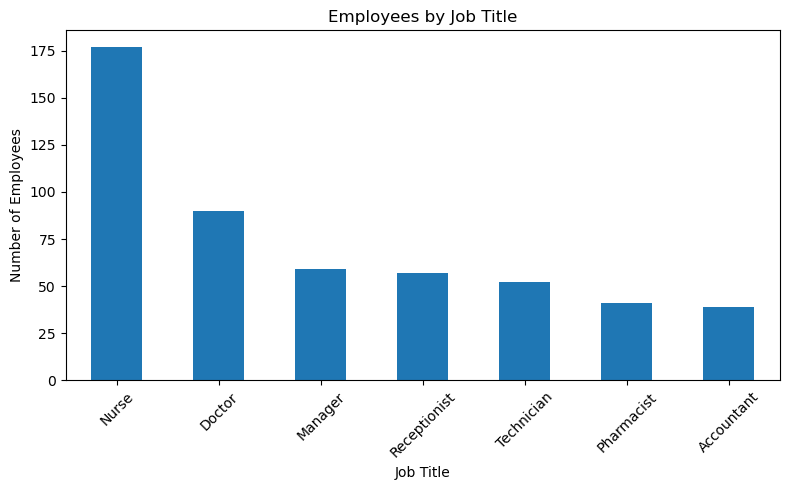

In [127]:
print("\nEmployees by Job Title")
print(df_employees["JobTitle"].value_counts())

plt.figure(figsize=(8, 5))
df_employees["JobTitle"].value_counts().plot(kind="bar")
plt.title("Employees by Job Title")
plt.xlabel("Job Title")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 2. Patients EDA


Patients by Gender
Gender
Male       618
Female     570
Unknown     12
Name: count, dtype: int64


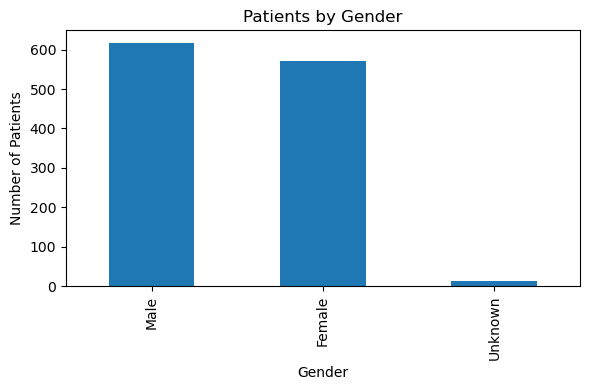

In [128]:
print("\nPatients by Gender")
print(df_patients["Gender"].value_counts())

plt.figure(figsize=(6, 4))
df_patients["Gender"].value_counts().plot(kind="bar")
plt.title("Patients by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

### 3. Appointments EDA


Appointments by Status
Status
Completed    1312
Scheduled     575
No Show       262
Cancelled     227
Name: count, dtype: int64


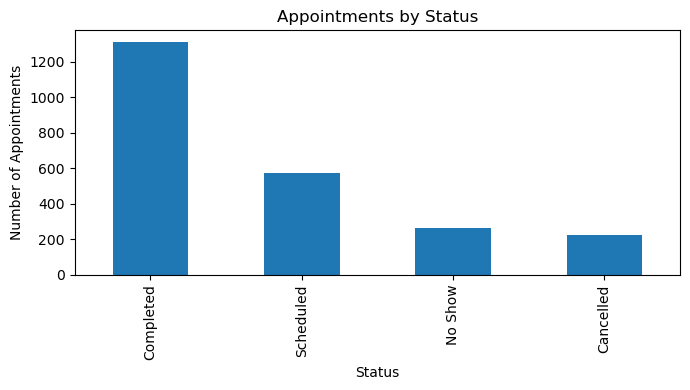

In [129]:
print("\nAppointments by Status")
print(df_appointments["Status"].value_counts())

plt.figure(figsize=(7, 4))
df_appointments["Status"].value_counts().plot(kind="bar")
plt.title("Appointments by Status")
plt.xlabel("Status")
plt.ylabel("Number of Appointments")
plt.tight_layout()
plt.show()

### 4. Admissions EDA


Admissions by Status
Status
Discharged     446
Admitted       131
Transferred     67
Name: count, dtype: int64


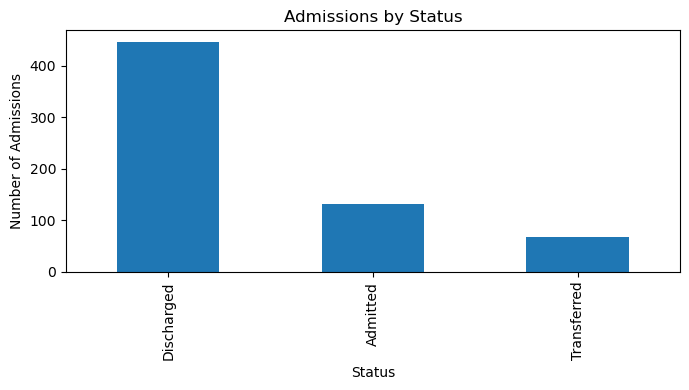

In [130]:
print("\nAdmissions by Status")
print(df_admissions["Status"].value_counts())

plt.figure(figsize=(7, 4))
df_admissions["Status"].value_counts().plot(kind="bar")
plt.title("Admissions by Status")
plt.xlabel("Status")
plt.ylabel("Number of Admissions")
plt.tight_layout()
plt.show()

### 5. Medical Records EDA


Top Diagnoses
Diagnosis
Fracture        330
Diabetes        307
Asthma          294
Migraine        294
Hypertension    282
Flu             275
Name: count, dtype: int64


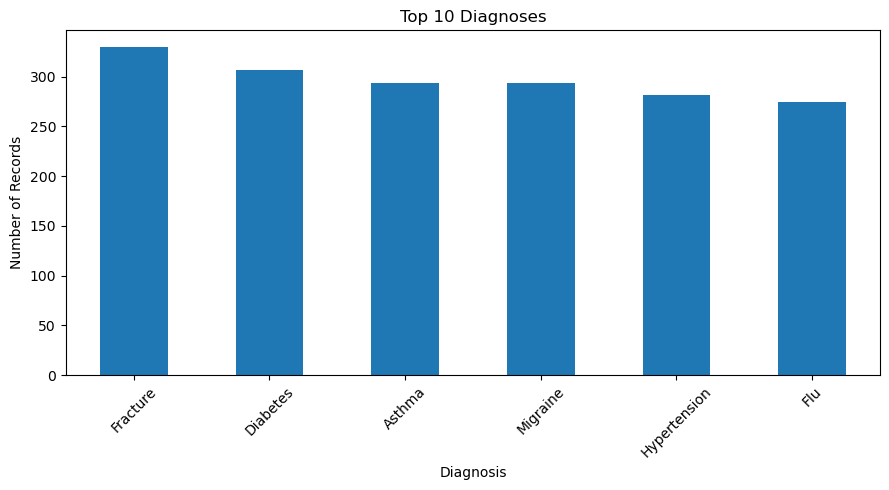

In [131]:
print("\nTop Diagnoses")
print(df_medical["Diagnosis"].value_counts().head(10))

plt.figure(figsize=(9, 5))
df_medical["Diagnosis"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6. Medicines EDA


Medicine Categories
Category
Cardiac       51
Analgesic     48
Antiviral     39
Diabetes      37
Vitamins      33
Antibiotic    30
Name: count, dtype: int64


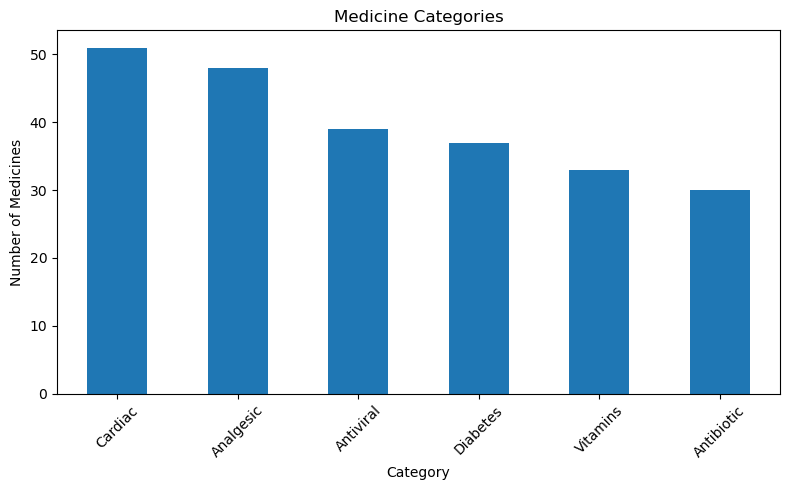

In [132]:
print("\nMedicine Categories")
print(df_medicines["Category"].value_counts())

plt.figure(figsize=(8, 5))
df_medicines["Category"].value_counts().plot(kind="bar")
plt.title("Medicine Categories")
plt.xlabel("Category")
plt.ylabel("Number of Medicines")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 7. Prescriptions EDA


Most Prescribed Medicines
MedicineID
10.0     73.0
158.0    73.0
100.0    73.0
174.0    71.0
159.0    68.0
11.0     68.0
34.0     65.0
162.0    65.0
39.0     64.0
9.0      63.0
Name: Quantity, dtype: float64


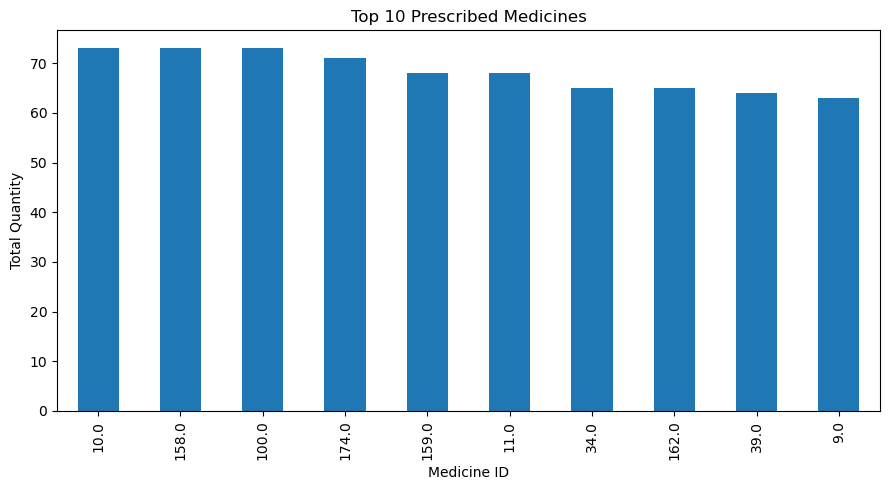

In [133]:
print("\nMost Prescribed Medicines")

medicine_counts = (
    df_prescriptions
    .groupby("MedicineID")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(medicine_counts)

plt.figure(figsize=(9, 5))
medicine_counts.plot(kind="bar")
plt.title("Top 10 Prescribed Medicines")
plt.xlabel("Medicine ID")
plt.ylabel("Total Quantity")
plt.tight_layout()
plt.show()

### 8. Invoices EDA


Invoice Statistics
count     1089.000000
mean     10381.074096
std       3456.618089
min       2052.900000
25%       7808.680000
50%      10489.010000
75%      13113.340000
max      18817.410000
Name: TotalAmount, dtype: float64


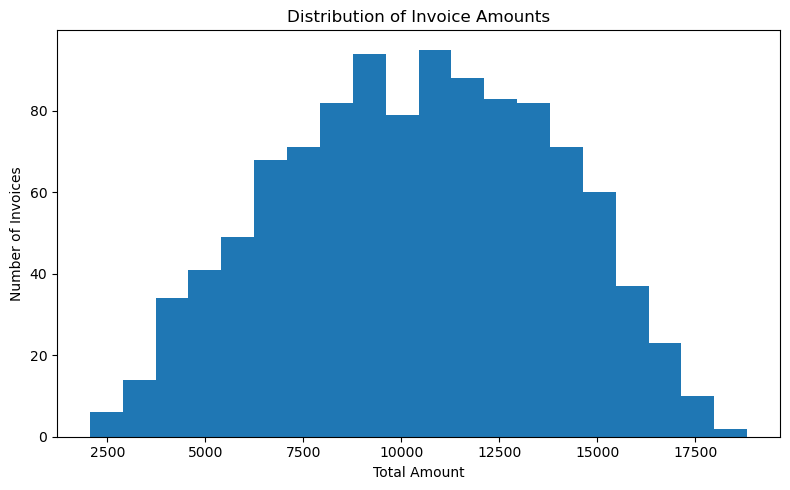

In [134]:
print("\nInvoice Statistics")
print(df_invoices["TotalAmount"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df_invoices["TotalAmount"].dropna(), bins=20)
plt.title("Distribution of Invoice Amounts")
plt.xlabel("Total Amount")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.show()

### 9. Payments EDA


Payment Methods
PaymentMethod
Card                 417
Bank Transfer        416
Cash                 414
Insurance            368
  insurance           11
  cash                10
  bank transfer        7
  card                 7
Name: count, dtype: int64


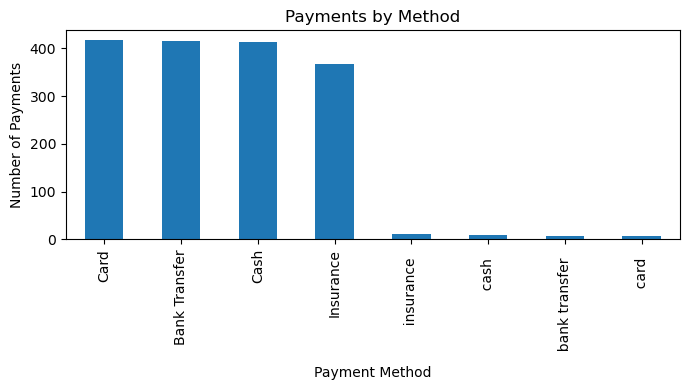

In [135]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Read Payments from RAW folder
df_payments = pd.read_csv("../data/raw/payments.csv")

# Payment Methods
print("\nPayment Methods")
print(df_payments["PaymentMethod"].value_counts())

# Plot
plt.figure(figsize=(7, 4))

df_payments["PaymentMethod"].value_counts().plot(kind="bar")

plt.title("Payments by Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Payments")

plt.tight_layout()
plt.show()

### 10. Attendance EDA


Attendance Status
Status
Present    2625
Late        385
Absent      277
Leave       179
Name: count, dtype: int64


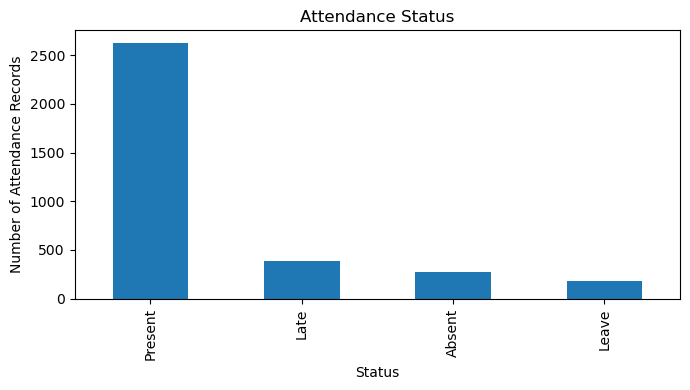

In [136]:
print("\nAttendance Status")
print(df_attendance["Status"].value_counts())

plt.figure(figsize=(7, 4))
df_attendance["Status"].value_counts().plot(kind="bar")
plt.title("Attendance Status")
plt.xlabel("Status")
plt.ylabel("Number of Attendance Records")
plt.tight_layout()
plt.show()

### 11. Rooms EDA


Rooms by Type
RoomType
Private         56
Emergency       53
ICU             41
Semi-Private    39
General         27
  general        2
  icu            1
  private        1
Name: count, dtype: int64


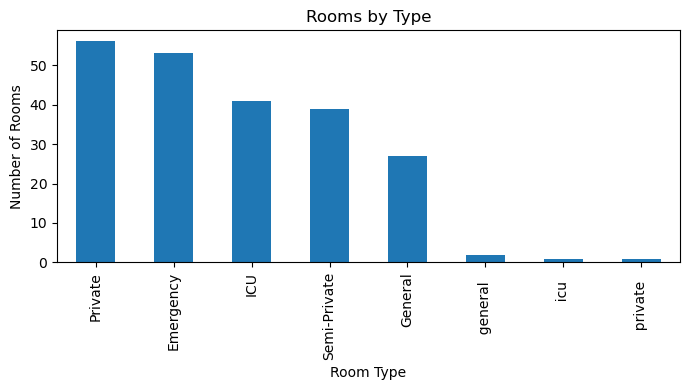

In [137]:
import pandas as pd
import matplotlib.pyplot as plt

# Read Rooms file
df_rooms = pd.read_csv("../data/raw/rooms.csv")

# Rooms by Type
print("\nRooms by Type")
print(df_rooms["RoomType"].value_counts())

# Plot
plt.figure(figsize=(7, 4))

df_rooms["RoomType"].value_counts().plot(kind="bar")

plt.title("Rooms by Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Rooms")

plt.tight_layout()
plt.show()

### 12. Correlation - Employees

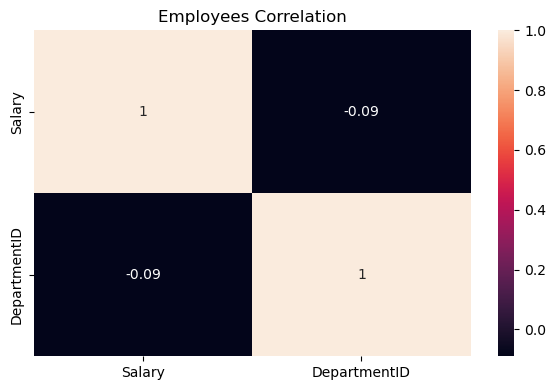

EDA FINISHED


In [138]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    df_employees[["Salary", "DepartmentID"]].corr(),
    annot=True
)
plt.title("Employees Correlation")
plt.tight_layout()
plt.show()


print("====================================")
print("EDA FINISHED")
print("====================================")